# İstanbul'daki Alışveriş Merkezlerinde Yapılan Alışverişlerin Ürün Kategorisi Bazında Analizi

## Eldeki Veri Setinin Beş Ana Soruda Analiz Edilip Gelecek Yatırım ve Düzenlemelere İlişkin Değerlendirilmesi


Bu veri seti, İstanbul özelinde belirli ürün kategorilerinde yapılan alışverişlerin alışveriş merkezlerine göre fiyat dağılımlarını göstermektedir. Veri seti Kaggle.com sitesinden alınmıştır. İlgili .csv dosyası .ipynb dosyası ile birlikte teslim edilmiştir. 
Analiz veri setinin Kaggle.com adresinden alınan kodu ile .ipynb dosyasına getirilmiştir. Sorgu zinciri ilk olarak ilgili veri setinin .ipynb dosyasına yüklenmesi ile başlar. 
"file_path =" bilgisine ilgili .csv dosyasının bağlantı yolu girilerek veri seti .ipynb dosyasına yüklenmiştir. 


### Analizde Dikkate Alınan Beş Soru

İlgili veri seti beş soruda incelenmiştir. Her sorudan elde edilen verinin ileriye dönük muhtemel risk ve imkanların tespit ve tavsiyelerinde etkili olabilecek sonuçlar getirmesine dikkat edilmiştir. Bu amaca yönelik olarak analiz boyunca incelenecek olan sorular aşağıdaki gibidir:

* Hangi cinsiyet hangi ödeme metodunda ne kadar harcama yapmıştır? 
* Her ödeme metodunda cinsiyete göre en çok ödeme ne kadardır ve alışveriş yapılan ürünün kategorisi nedir?
* 18-25, 26-30, 31-40, else yaş aralığı en çok hangi ödeme methodunu tercih ediyor?
* Hangi kategorilerde hangi ödeme metoduyla ne kadar ücret ödenmiş? 
* Hangi alışveriş merkezinde en pahalı hangi kategoriler tercih ediliyor?

Sorular ilgili veri setinin yazdırılıp satır ve sütunlarının incelenmesi ile oluşturulmuştur. Muhtemel ilişki bağları göz önünde bulundurulmuştur.


In [2]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "istanbul_sales_data.csv.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "ardayavuzkeskin/istanbul-retail-trends-a-customer-behavior-dataset",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

c:\Users\nuray\Desktop\WS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\nuray\AppData\Local\Temp\ipykernel_16652\3163250858.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:   invoice_no customer_id  gender   age    category  quantity    price  \
0    I100001     C313884  Female  28.0    Clothing       2.0   600.16   
1    I100002     C311565    Male  22.0  Technology       1.0  2100.00   
2    I100003     C366599    Male  20.0    Clothing       1.0   300.08   
3    I100004     C388172  Female  66.0       Books       5.0    75.75   
4    I100005     C389076  Female  53.0   Cosmetics       4.0   162.64   

  payment_method invoice_date shopping_mall  
0    Credit Card   2023-05-18  Istinye Park  
1    Credit Card   2024-02-12  Zorlu Center  
2           Cash   2023-09-11     Metrocity  
3    Credit Card   2024-01-28  Metropol AVM  
4           Cash   2023-10-24   Cevahir AVM  


## Gerekli Kütüphanelerin İndirilmesi

.csv dosyasının analizi için gerek duyulabilecek temel kütüphaneler öncelikle indirilmiştir. Veri setinde gerekli sayısal işlemler için "numpy", .csv dosyasındaki veriyi okuma ve işlemeye yardımcı "pandas" ve veri görselleştirmede etkili "matplotlib" kütüphaneleri öncelikle indirilmiştir. 
İleriki sorgularda kapsamlı bir çubuk grafikte istatiksel veriyi görselleştirmede ihtiyaç duyulması nedeni ile "seaborn" kütüphanesi indirilmiştir.

## Veri Setinin Yazdırılması/İncelenmesi

Gerekli kütüphanelerin indirilmesinin ardından ilgili veri setini okuma komutu ile ilk 30 kaydı yazdırılmıştır.

Çıkan tabloda kolonlar, satır içerikleri incelenmiştir. Bu aşamada ayrıca yukarıda geçen sorular da bu aşamada tablodaki mevcut bilgilerin incelenmesi ile oluşturulmuştur. 

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

istanbul_sales_data = pd.read_csv("istanbul_sales_data.csv.csv")
istanbul_sales_data.head(20)

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I100001,C313884,Female,28.0,Clothing,2.0,600.16,Credit Card,2023-05-18,Istinye Park
1,I100002,C311565,Male,22.0,Technology,1.0,2100.00,Credit Card,2024-02-12,Zorlu Center
2,I100003,C366599,Male,20.0,Clothing,1.0,300.08,Cash,2023-09-11,Metrocity
3,I100004,C388172,Female,66.0,Books,5.0,75.75,Credit Card,2024-01-28,Metropol AVM
4,I100005,C389076,Female,53.0,Cosmetics,4.0,162.64,Cash,2023-10-24,Cevahir AVM
5,I100006,C335761,Female,56.0,Food & Beverage,5.0,26.15,Credit Card,2024-03-04,Kanyon
6,I100007,C331672,Male,30.0,Shoes,2.0,600.16,Credit Card,2023-07-23,Zorlu Center
7,I100008,C340286,Male,34.0,Food & Beverage,1.0,5.23,Cash,2024-09-26,Forum Istanbul
8,I100009,C321970,Male,46.0,Technology,1.0,5250.00,Credit Card,2023-12-25,Istinye Park
9,I100010,C329330,Female,63.0,Books,3.0,45.45,Credit Card,2024-08-13,Metrocity


## .info() ve .describe() Sorguları

.info() sorgusu ile tablonun toplamda 504 satır, 10 sütundan oluştuğu gözlemlenmiştir. Her bir sütunun adı ve veri tipi incelenmiş toplamda 7 string, 3 float64 veri türü olduğu görülmüştür. 

.describe() sorgusu ile yaş, miktar ve fiyat kolonlarının toplam satır sayısı, ortalama, standat sapma, minimum ve maksimum değerleri ve her bir çeyreklikteki değerlerine ulaşılmıştır. 

Sorgunun en sonuna yazılan .round(2) komutu ile virgülden sonra gelen takrarlı rakamlar azaltılıp okunurluğu kolaylaştırılmıştır.

In [4]:
istanbul_sales_data.info()

istanbul_sales_data.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      504 non-null    str    
 1   customer_id     503 non-null    str    
 2   gender          503 non-null    str    
 3   age             503 non-null    float64
 4   category        503 non-null    str    
 5   quantity        503 non-null    float64
 6   price           503 non-null    float64
 7   payment_method  503 non-null    str    
 8   invoice_date    503 non-null    str    
 9   shopping_mall   503 non-null    str    
dtypes: float64(3), str(7)
memory usage: 39.5 KB


,age,quantity,price
count,503.00,503.00,503.00
mean,40.86,2.70,1206.42
std,13.42,1.32,3064.51
min,18.00,1.00,5.23
25%,30.00,2.00,41.90
50%,39.00,2.00,143.36
75%,51.00,4.00,900.24
max,72.00,5.00,26250.00


In [5]:
print(istanbul_sales_data.columns)

Index(['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity',
       'price', 'payment_method', 'invoice_date', 'shopping_mall'],
      dtype='str')


## 1. Hangi cinsiyet hangi ödeme metodunda ne kadar harcama yapmıştır? 

Tablonun incelenmesinin ardından tablo ile ilgili oluşturulan soruların incelenmesine geçilmiştir. 
İlk olarak her bir kategoride gerçekleşen satışların cinsiyetlere göre fiyat dağılımlarını görmeyi sağlamak için .groupby() komutu ile cinsiyet ve ödeme şekilleri gruplandırılmıştır. 
Hangi cinsiyetin hangi ödeme metodunda toplamda ne kadar ödeme yaptığını görmek için "price" kolonuna .sum() komutu ile toplama işlemi uygulanmıştır.
Son olarak hangi cinsiyetin hangi ödeme metodu ile en fazla ödeme yaptığını görmek için .sort_values() fonksiyonu ile fiyatlar yüksekten azalana doğru sıralanmıştır(ascending=False). 

### Kadın ve Erkeklerde En Çok Tercih Edilen Ödeme Yöntemi: Kredi Kartı

Kodlama ile çıkan sonuçta en yüksek harcamanın her iki cinsiyette de kredi kartı ödemesi yöntemi ile gerçekleştiği gözlemlenmiştir. Bu sonuç listede adı geçen alışveriş merkezlerinin satış imkanlarını kolaylaştırmak ve böylece satışları artırmak adına kredi kartı ile ödeme imkanını kolaylaştırıcı yollara başvurmuş olabileceği yorumunu destekler.

In [6]:
# Cinsiyet ve ödeme türüne göre toplam harcamayı hesaplıyoruz. Hangi cinsiyetin en çok hangi ödeme türünü kullandığını görmek için gruplama yapıyoruz.
spending_summary = istanbul_sales_data.groupby(['gender', 'payment_method'])['price'].sum().sort_values(ascending=False)

print(spending_summary)

gender  payment_method
Female  Credit Card       215468.11
Male    Credit Card       169522.93
        Cash               99077.74
        Debit Card         78783.64
Female  Cash               25072.50
        Debit Card         18905.32
Name: price, dtype: float64


### Pivot Tablo

Aşağıda hangi cinsiyetin hangi ödeme yöntemi ile ne kadar alışveriş yapıyor sorusunu cevaplayan bir pivet tablo oluşturulmuştur.
"index" kısmına yazılan "gender" tablonun satırlarını, "columns" kısmına yazılan "payment_method" tablonun kolonlarını oluşturmaktadır. Son olarak "values" kısmı tablonun içerisine girilecek bilgilerin ne olacağını göstermektedir. "aggfunc" ile toplama işlemi yaptığımız harcamalar tablonun içerisine girilecek bilgileri oluşturmaktadır.

En sonunda toblo, cinsiyete göre azalan şekilde sıralanmıştır.

In [7]:
# Ödeme türlerini sütunlara, cinsiyetleri satırlara yerleştiren pivot tablo
pivot_spending = istanbul_sales_data.pivot_table(
    index='gender',          # Satırlar
    columns='payment_method', # Sütunlar (Ödeme Türleri)
    values='price',     # Hesaplamak istediğimiz değer
    aggfunc='sum'             # Toplam harcama
).sort_values(by='gender', ascending=False)

print(pivot_spending)

payment_method      Cash  Credit Card  Debit Card
gender                                           
Male            99077.74    169522.93    78783.64
Female          25072.50    215468.11    18905.32


## 2. Her ödeme metodunda cinsiyete göre en çok ödeme ne kadardır ve alışveriş yapılan ürünün kategorisi nedir?

Aşağıda yapılan kodalamada bu sefer de her bir cinsiyetin en çok harcama yaptığı ürün kategorisi tespit edilmiştir. Yukarıdaki kodlamaya benzer bir kodlama ile ödeme şekilleri, cinsiyet ve ürün kategorisi gruplandırılarak iki cinsiyete göre her bir ürün kategorisindeki her bir ödeme şekilinin toplam harcaması çıkarılmıştır. Ancak buradan sonraki işlemleri gerçekleştirebilmek için kodun sonuna .reset_index()fonksiyonu yazarak tabloyu DataFrame'e çevirdik.
Elde edilen değerleri hangi cinsiyetin en çok hangi kategoride harcama yaptığını bulabilmek için sıralamak ve benzer değerleri eleyip en üstteki ilk değeri tutabilmek için ise .sort_values ve ödeme şekli ve cinsiyet kolonlarını içerecek şekilde .drop_duplicates() fonksiyonunu kullandık. 

### Her İki Cinsiyette En Çok Harcama Yapılan Ürün Kategorisi: Teknoloji

Yazdırılan kodlamada çıkan sonuçlara göre yalnızca nakit kartla ödeme yapmayı tercih eden kadınlar hariç her ödeme şeklinde her iki cinsiyette en çok harcamayı teknoloji kategorisine yapmaktadır. 
Bu durum teknoloji ürünlerinin daha çok tercih edildiğini göstermez. Teknoloji ürünlerinin fiyatının yüksek olmasından kaynaklanmaktadır. Nitekim tablo incelendiğinde de adet olarak diğer ürünlerdeki adet tercihlerinden daha az sayıda alım gerçekleştirilse de teknoloji ürünüleri harcama listesinde ilk sırayı almaktadır.
Nakit kartla ödeme yapmayı tercih eden kadınların ise en çok harcama yaptığı ürün kategorisi ayakkabıdır. Ayakkabı için nakit kart tercihi konusunda doğrudan bir korelasyon kuracak veri elde bulunmamakla birlikte, teknoloji ürünlerinin yüksek fiyatı kredi kartına taksiti gerektirirken ayakkabının nakit kartla ödeme imkanının daha kolay olması ile zayıf bir bağlantısı olduğu düşünülmektedir.

In [ ]:
# 1. Gruplama yapıp .sum() ile toplam harcamayı bulduk ve reset_index() ile DataFrame'e çevirdik.
df_grouped = istanbul_sales_data.groupby(['payment_method', 'gender', 'category'])['price'].sum().reset_index()

# 2. Harcamaya göre büyükten küçüğe sıraladık.
df_sorted = df_grouped.sort_values(by='price', ascending=False)

# 3. Her 'payment_method' ve 'gender' ikilisi için yalnızca ilk (en yüksek) satırın gelmesini istedik.
result = df_sorted.drop_duplicates(subset=['payment_method', 'gender'])

print(result)

   payment_method  gender    category      price
20    Credit Card  Female  Technology  169050.00
28    Credit Card    Male  Technology  141750.00
12           Cash    Male  Technology   79800.00
41     Debit Card    Male  Technology   66150.00
4            Cash  Female  Technology   16800.00
34     Debit Card  Female       Shoes    8702.32


## 3. 18-25, 26-35, 36-45, 45-55, 55-65, 65+ yaş aralığı en çok hangi ödeme methodunu tercih ediyor?

Bu soruyu cevaplamak için tabloda sıralanmış yaş aralıklarının çok fazla benzersiz değer içeriyor olabileceği düşüncesi ile yaşları belirli yaş aralıklarına alarak tabloyu sınırlandırmanın makul olacağı düşünülmüştür. Bu yaş aralığının kurulması için ise if koşulu ile sağlanmış bir tanım fonksiyonu kurulmuştur. 
Buna göre eğer yaş 18-25 dahil olmak üzere bu yaş aralıklarındaysa "18-25",
eğer yaş 26-35 dahil olmak üzere bu yaş aralıklarındaysa "26-35",
eğer yaş 36-45 dahil olmak üzere bu yaş aralıklarındaysa "36-45",
eğer yaş 46-55 dahil olmak üzere bu yaş aralıklarındaysa "46-55",
eğer bu koşulların hiçbirine uymuyorsa "65+" bilgilerinin girilmesi koşuluyla ve .apply() fonksiyonu ile bir "age_group" sütunu oluşturulmuştur.
Böylelikle soruda geçen yaş aralıklarında hangi ödeme şekillerinin tercih edildiğinin listelendiği bir sorgu oluşturulmuştur. 
Her yaş gurubuna denk gelen ödeme yöntemlerinde gerçekleştirilen işlem sayılarını bulabilmek için bu işlem sayılarının satır sayılarını bize getiren .size() fonksiyonundan faydalanılmıştır. 
Yukarıdaki kodlamalarla benzer şekilde yineleyen yaş aralıklarını temizlemesi için .drop_duplicates() fonksiyonu kullanılmıştır.

### Yaş İlerledikçe Kredi Kartı Kullanımı Tercihi Artıyor

Yapılan sorguda çıkan sonuca göre her yaz aralığında kredi kartı kullanımı yaş aralığında ileri yaşlara gidildikçe daha çok artmaktadır. 45-55 yaş aralığından sonra kısmen tercih azalsa da hala devam eden tüm yaş aralıklarında en çok tercih edilen ödeme yöntemi olarak ilk sıradadır. 
18-25 yaş aralığında ise kredi kartından ziyade nakit kart kullanımının daha fazla olmasının ilgili yaş aralığının üniversite öğrencilik yaş aralığına denk geliyor olması ile ilişkisi olabilir. Bu yaş aralığında aileden gelen harçlık ya da öğrenim bursları bu yaş aralığındaki kişileri nakit kart kullanımına teşvik ediyor olabilir. Doğrudan bir korelasyon kuracak veri elde bulunmamaktadır.

In [ ]:
def yas_grubu_belirle(age):  #Yaş sütununu belirli yaş gruplarına ayıran if koşulu tanımlandı.
    if 18 <= age <= 25:
        return '18-25'
    elif 26 <= age <= 35:
        return '26-35'
    elif 36 <= age <= 45:
        return '36-45'
    elif 46 < age <= 55: 
        return '45-55'
    elif 56 < age <= 65:  
        return '55-65'
    else:
        return '65+'

#Tanımlanan if koşulunu .apply() ile 'age_group' adında yeni bir kolonda veri setine yazdırdık.
istanbul_sales_data['age_group'] = istanbul_sales_data['age'].apply(yas_grubu_belirle)

#Gruplama sonucunda satır sayısını (adetini) bulmak için .size() ile her bir ödeme yönteminin yaş aralığına göre toplam sayısını bulduk.
df_pref_pay_met_by_age = istanbul_sales_data.groupby(['age_group', 'payment_method']).size().reset_index(name='islem_sayisi')
df_most_pay_met_by_age = df_pref_pay_met_by_age.drop_duplicates(subset=['age_group'])
print(df_pref_pay_met_by_age)

   age_group payment_method  islem_sayisi
0      18-25           Cash            20
1      18-25    Credit Card            16
2      18-25     Debit Card            28
3      26-35           Cash            33
4      26-35    Credit Card            69
5      26-35     Debit Card            40
6      36-45           Cash            42
7      36-45    Credit Card            47
8      36-45     Debit Card            31
9      45-55           Cash            11
10     45-55    Credit Card            50
11     45-55     Debit Card            18
12     55-65           Cash            11
13     55-65    Credit Card            41
14     55-65     Debit Card             3
15       65+           Cash             9
16       65+    Credit Card            34


## 4. Hangi kategorilerde hangi ödeme metoduyla ne kadar ücret ödenmiş? Her kategori bazında yapılan ödeme çeşitlerinin ortalaması nedir?

Bu soru aracılığıyla da bu sefer ürün kategorilerine göre gerçekleşen her bir ödeme yönteminin fiyat listesi incelenmiştir. 
Listeyi oluşturmak için öncelikle ürün kategorisi ve ödeme methodu bazında liste gruplandırılmıştır(.grupby()). Daha sonrasında her bir ürün kategorisinde gerçekleşen farklı satın alma yöntemlerine karşılık gelen harcamayı görmek için tablonun fiyat kolonuna .sum() fonksiyonu uygulanmıştır. .columns ile bu işlemin sonuçları yeni adlandırılmış kolonlarla listelenmiştir.
Bir sonraki aşamada Liste ürün kategorisi ve ödeme yöntemine göre yeniden indekslenmiştir(.set_index()). Böylece her satırda gereksiz yinelenen ürün kategorileri, kendi grubunda bir kez gelecek şekilde yeniden listelenmiştir.

### Fiyat Ortalaması En Yüksek İlk Üç Ürün Kategorisi: Teknoloji, Ayakkabı ve Giyim

Sonucu yazdırılan listede çıkan veriye göre fiyat ortalaması her üç ödeme yönteminde de ilk üçte yer alan ürün kategorilerinin sırasıyla teknoloji, ayakkabı ve giyim olduğu gözlemlenmiştir. Bu ürünleri takip eden diğer kategoriler aralarında az farkla kozmetik ve oyuncak kategorileridir. Bu veriye göre bakıldığında müşterilerin alışveriş merkezlerinde harcama yapma motivasyonu büyük oranda teknoloji, giyim(ayakkabı dahil), kozmetik ve oyuncak çerçevesinde gerçekleşmektedir. Yemek ve atıştırmalık kategorisindeki fiyat oranlarının düşüklüğü, müşterilerin yemek yemek motivasyonu ile alışveriş merkezlerini öncelikle tercih etmediğini göstermektedir. 



In [ ]:
#Kategori ve ödeme yöntemine göre gruplanmış toplam fiyat ve ortalama hesaplama(virgülden sonra iki basamak olacak şekilde)
df_price_sum = istanbul_sales_data.groupby(['category', 'payment_method'])['price'].agg(['sum', 'mean']).reset_index().round(2)

#Yeni kolonların çıkacak olan tablodaki isimlerini atama
df_price_sum.columns = ['category', 'payment_method', 'total_price', 'pay_met_mean']

#Ürün kategorisini ve ödeme metoduna çok indeksleme uygulayarak kategori isimlerinin kendi grubunda bir kez geçmesini sağlama 
df_price_sum_mean = df_price_sum.set_index(['category', 'payment_method'])
df_price_sum_mean

total_price  pay_met_mean
category        payment_method                           
Books           Cash                 469.65         52.18
                Credit Card         1333.20         39.21
                Debit Card          1030.20         57.23
Clothing        Cash                8402.24       1050.28
                Credit Card        48612.96        823.95
                Debit Card          7502.00        577.08
Cosmetics       Cash                2724.22        118.44
                Credit Card         1667.06        111.14
                Debit Card          1992.34         90.56
Food & Beverage Cash                 230.12         11.51
                Credit Card          794.96         16.91
                Debit Card            52.30         13.08
Shoes           Cash               12303.28       1025.27
                Credit Card        19505.20        696.61
                Debit Card         18905.04        675.18
Souvenir        Cash                 481.85         43.80
                Credit Card          879.90         48.88
                Debit Card          1089.40         72.63
Technology      Cash               96600.00       6440.00
                Credit Card       310800.00       7400.00
                Debit Card         66150.00       5088.46
Toys            Cash                2938.88        104.96
                Credit Card         1397.76         99.84
                Debit Card           967.68        138.24

### matplotlib ve seaborn Kütüphaneleri ile Kategorilere Ayrılmış Çubuk Grafik Oluşturma

Yukarıdaki soruyu cevaplayan veri listesi yazdırıldıktan sonra, ilgili veri listesinin sadece toplam fiyatlar bazında çubuk grafikteki kategorilere ayrılmış görünümü yazdırılmıştır. 
Buna göre öncelikle görsel ve istatiksel grafik çalışmalarında yardımcı kütüphaneler olan matplotlib ve seaborn kütüphaneleri içeri aktarılmıştır. 

Grafikte yer alması istenen veri oluşturulmuştur. Bu veri yukarıdaki sorguyla hemen hemen aynı olup her bir ürün kategorisine denk gelen ödeme yöntemlerinin toplam fiyatları birinci kodlamada istenmiştir.

İkinci kodlamada grafiğin sayfada kaplayacağı alan en boy boyutunda plt.figure() fonksiyonu ile belirtilmiştir.

Üçüncü kodlamada seaborn kütüphanesi aracılığıyla .barplot() fonksiyonu çağırılmış ve bir bar grafiği istenmiştir. Fonksiyonun içerisine grafiğe dair yazdırılması istenen bilgiler girilmiştir. Verinin 1. kodlamada tanımlanmış olan "df_plot" kodlamasından alınması istenmiştir. Grafiğin x ekseninde ürün kategorilerinin isimlerinin, y ekseninde ise fiyatın yazdırılması sağlanmıştır. "hue" yanı renk aralıklarının ise ödeme metodlarına göre gruplanması sağlanmıştır. Grafikte kullanılcak renk skalası ise 'viridis' (renk körleri için tavsiye edilen renk paletlerinden birisi) olarak seçilmiştir.

4'üncü aşamada her çubuğun üzerinde gösterdiği fiyatın rakamla da yazılı olması için gerekli for döngüsü kullanılmıştır. Toplam fiyattaki her bir ödeme yöntemine karşılık gelen bir fiyatın tam sayı formatında(fmt='%.0f'), 9 font büyüklüğünde, 30 derece eğiklikte ve bar ile rakamlar arasındaki boşluğun 3 değerinde olması istenmiştir. 

5'inci aşamada yazdırılacak olan grafiğin başlıklandırılması ve eksenlerinin isimlendirilmesi yapılmıştır. Buna göre plt.title() ile grafiğin başlığı 'Kategorilere Göre Ödeme Yöntemlerinin Toplam Ücret Dağılımı', 14 font büyüklüğünde, kalın punto olarak belirlenmiştir. plt.xlabel() ile x ekseninin adı 'Ürün Kategorisi', plt.ylabel() ile y ekseninin adı 'Toplam Ücret' olarak ve 12 font büyüklüğünde belirlenmiştir. 

6'ncı aşamada plt.xticks() fonksiyonu ile x eksenindeki ürün kategorilerinin açısının sağa doğru 45 derece eğiklikte  (rotation=45, ha='right') olması istenmiştir.

7'nci aşamada Çubuk grafiğin üst kısımlarına yazdırılması istenen rakamların (en uzun çubuğun grafik üst sınırına yakın bir yerde olmasından dolayı) grafiğin üst sınırı ile çakışmasını önlemek için y ekseni "df_plot['price'].max() * 1.15" çarpma işlemi ile biraz daha yukarı doğru büyütülmüştür.

8'inci aşamada bize göre sağ üst köşede yer alan ödeme yöntemlerinin çubuk grafiği rengini gösteren bilgi kutusunun yazdırılması plt.legend() fonksiyonu çağırılmıştır. Bilgi kurusunun başlığı 'Ödeme Yöntemi' olarak belirlenmiş, bilgi kutusunun ölçüleri 1,5'e 1 olarak oluşturulmuştur. Yer alacağı konum bilgisi (loc='upperleft') ise bilgisayar konumuna göre sol üst köşe olarak istenmiştir. 

Son olarak 9'uncu aşamada plt.grid() ile grafiğin ızgarası y eksenindeki fiyat aralıklarından başlayıp x ekseni boyunca yan yana kısa çizgiler halinde (--) oluşturulması istenmiştir. plt.tight_layout() ile de grafiğin sorgu sayfasını dolduracak şekilde yazdırılması sağlanmıştır. plt.show() ile de grafiğin yazdırılması komutu verilmiştir.

Grafik hakkında verilecek bilgiler yukarıdaki "Fiyat Ortalaması En Yüksek İlk Üç Ürün Kategorisi: Teknoloji, Ayakkabı ve Giyim" başlığında ilgili listenin incelenmesi sırasında verilmiştir. 

Bu grafikte ayrıca oranların görünümünün istenmesi grafikte kargaşa yaratacağından oranların görüntülenmesi istenmemiştir. Sadece fiyat görünümü ile dahi teknoloji, ayakkabı ve giyim kategorileri haricindeki diğer kategorilerin çubuk grafiği bazında karşılaştırmasını yapmak zordur. Çünkü teknoloji kategorisindeki çok yüksek değerler grafiği dengeli bir oranda görüntülemeyi zorlaştırmıştır. Bu grafikte en kolay yapılabilecek okuma en yüksek satın almanın teknoloji kategorisinde gerçekleştiği okuması olacaktır. 


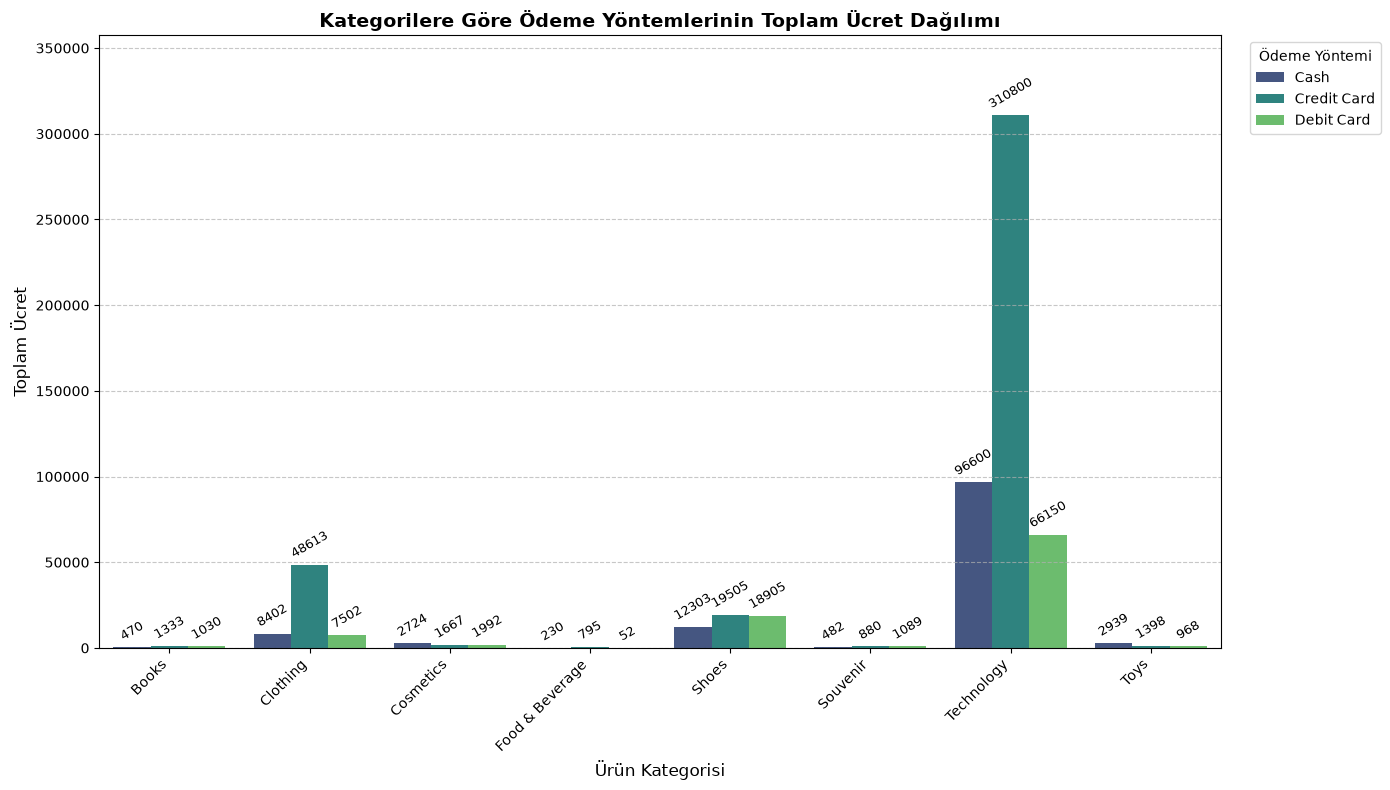

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Veriyi hazırlama
df_plot = istanbul_sales_data.groupby(['category', 'payment_method'])['price'].sum().reset_index()

# 2. Grafik boyutunu ayarlama (Yazıların sığması için yüksekliği biraz artırdık)
plt.figure(figsize=(14, 8))

# 3. Seaborn ile gruplanmış çubuk grafik oluşturma ve ax değişkenine atama
ax = sns.barplot(
    data=df_plot,
    x='category',           
    y='price',              
    hue='payment_method',   
    palette='viridis'       
)

# 4. Her barın üzerine fiyat bilgilerini yazdırma
for container in ax.containers:
    ax.bar_label(
        container, 
        fmt='%.0f',          # Küsurat kalabalık olmasın diye tam sayı formatı 
        padding=3,           # Bar ile yazı arasındaki boşluk
        fontsize=9,          # Yazı boyutu
        rotation=30          # Sıkışmayı önlemek için hafif açı
    )

# 5. Başlık ve Eksen Etiketleri
plt.title('Kategorilere Göre Ödeme Yöntemlerinin Toplam Ücret Dağılımı', fontsize=14, fontweight='bold')
plt.xlabel('Ürün Kategorisi', fontsize=12)
plt.ylabel('Toplam Ücret', fontsize=12)

# 6. X ekseni etiketlerini döndürme
plt.xticks(rotation=45, ha='right')

# 7. Yazıların grafiğin üst sınırına çarpıp kesilmemesi için Y eksenini biraz genişletiyoruz
plt.ylim(0, df_plot['price'].max() * 1.15)

# 8. Lejant (Açıklama kutusu) konumu
plt.legend(title='Ödeme Yöntemi', bbox_to_anchor=(1.02, 1), loc='upper left')

# 9. Izgara ve Gösterim
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 5. Hangi alışveriş merkezinde en pahalı hangi kategoriler tercih ediliyor?
Bu soruyu cevaplamak için yine DataFrame kullanılarak en çok ödeme yapılan ürünlerin satın alındığı alışveriş merkezleri listelenmiştir. İlk olarak alış veriş merkezleri ve ürün kategorileri .groupby() fonksiyonu ile gruplandırılmıştır. Fiyatta ise en yüksek değerlerin getirilmesi ['price'].max() fonksiyonu ile istenmiş, .sort_values(ascending=False) ile de en yüksek ödemelerin listenin başında kalması için büyükten küçüğe sıralanması istenmiştir. 
Farklı kategorilerde aynı alışveriş merkezlerindeki satın almalar da listeleneceği için ve biz yalnızca her alışveriş merkezinde en yüksek ödemeyi görmek istediğimiz için .drop_duplicates(subset='shopping_mall') fonksiyonu kullanılarak sıralanacak olan listede yalnızca en yüksek ödemenin yapıldığı ürün kategorilerinin satın alındığı alışveriş merkezlerinin yazdırılması sağlanmıştır.

### Satın Alınan Ürün Adetleri İncelendiğinde En Pahalı Alışveriş Merkezi: From İstanbul

Listede sadece en yüksek ödemenin yapıldığı alışveriş merkezleri sıralanmamış ayrıca satın alınan ürünlerin kaç adet alındığı da listelenmiştir. adet bilgileri ile fiyatlar karşılaştırıldığında Metrocity'de toplam 26250 tl'ye 5 adet ürün alınmışken, Forum İstanbul'dan 15750 tl'ye 3 adet ürün alınmıştır. 
Eldeki verilerde bu satın alma işlemlerinin aynı üründen 5 tane mi yoksa aynı kategoride 5 farklı ürün mü alındığı hakkında net bir ayırıcı nitelik verilmediğinden ödenen tutarın birim fiyatını net söylemek zordur. 
Ancak Metrocity ve Forum İstanbul'daki satın almalar karşılatırıldığında Metrocity'de 5 ürüne 26250 tl ödenirken Forum İstanbul'da sadece 3 ürün 15750 tl tutmaktadır. Bu da alınan bu üç ürün her ne ise Metrocity'de satın alınan 5 ürüne göre en azından bir ya da ikisi daha pahalıdır. Bu da Forum İstanbul'da yapılan alışverişteki en azından bir ya da iki ürünün fiyatının daha pahalı olduğu yorumunu getirir. Birim fiyatlar ve satın alınan ürünlerin aynılık ya da farklılığı konusunda yeterli veri bulunmadığından her bir ürünün birim fiyatı hakkında konuşmak mümkün görünmemektedir. 

In [ ]:
#Fiyata göre karşılaştırılması istenen kolonların gruplandırılması, fiyatın ürün kategorisine göre en yüksek değerlerinin istenmesi ve bunların azalır şekilde listelenmesi
df_grouped_malls = istanbul_sales_data.groupby(['shopping_mall', 'category', 'quantity'])['price'].max().sort_values(ascending=False).reset_index()

#Tekrar eden alışveriş merkezi isimlerinin kaldırılarak sadece en yüksek fiyatlı ilk alışveriş merkezinin kalmasını sağlama
df_sorted_malls = df_grouped_malls.drop_duplicates(subset='shopping_mall')
df_sorted_malls

,shopping_mall,category,quantity,price
0,Metrocity,Technology,5.0,26250.00
1,Forum Istanbul,Technology,3.0,15750.00
2,Cevahir AVM,Technology,2.0,10500.00
3,Istinye Park,Technology,4.0,8400.00
4,Metropol AVM,Technology,4.0,8400.00
6,Emaar Square Mall,Technology,3.0,6300.00
9,Zorlu Center,Technology,1.0,5250.00
14,Akasya,Technology,2.0,4200.00
26,Kanyon,Clothing,4.0,1200.32
